# 01 · Quickstart: two particles in one cavity

This notebook builds a two-particle coherent-scattering system from physical parameters, inspects
it, and calculates its optical (homodyne, heterodyne) and mechanical (position) spectra. It then
identifies the peaks as the normal modes of the drift matrix, measures the optical spring shift,
and checks that the system has a steady state - which, with levisim's built-in tweezer phases,
it would not.

**Runtime:** about 5 s. **Background:** [Getting started](../../docs/getting_started.md),
[Spectra of several particles in one cavity](../../docs/guide/cavity_spectra.md) and
[Conventions](../../docs/concepts/conventions.md) (units, Fourier convention, spectral
normalisation).

Run it from a clone of the repository with `pip install -e .`, or with `PYTHONPATH` pointing at the
repository root.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import kHz, Hz, degrees
from levisim.multiphysics.covariance import steady_state_covariance, dimension_covariance
from levisim.analysis.gaussian_states import mean_phonon_numbers
from levisim.multiphysics.enums import QuantumLinearTheoryMethod
from levisim.multiphysics.multitrap import MultiTrap
from levisim.multiphysics.utils.shelf import DEFAULT_cavity_kwargs, DEFAULT_gas_kwargs

set_plt_rcParams_to_xmgrace_style()
LAM = QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL

## 1. Build the system

With no `toy_params`, `MultiTrap` builds each particle from the physics: a silica bead (radius
about 60 nm) in its own 1064 nm tweezer, at a node of the cavity standing wave. The trap
frequencies follow from the tweezer waist and power, and the coherent-scattering couplings $g_{j_n}$
from the bead's polarisability and the overlap of the tweezer and cavity fields. The built-in tweezers
have optical phases 0° and 90°; `φn_dict={2: 30 * degrees}` sets the second to $\phi_2 = 30^\circ$
instead, because with 90° this system has no steady state (section 5).

`ω_range` can be a list of grids, which `MultiTrap` stitches together: here a coarse grid over
$\pm 170$ kHz and fine grids (10 Hz steps) around the mechanical peaks at positive and negative
frequency. Remember that frequencies are angular: `kHz` is $2\pi \times 10^3$ rad/s.

In [ ]:
ω_range = [
    np.arange(-170, 170, 0.5) * kHz,     # background
    np.arange(125, 165, 0.01) * kHz,     # mechanical peaks, anti-Stokes side
    np.arange(-165, -125, 0.01) * kHz,   # mechanical peaks, Stokes side
]
mtrap = MultiTrap(
    num_traps=2,
    Cartesian_axes_per_trap=2,              # x and y of each particle
    φn_dict={2: 30 * degrees},              # optical phase of the second tweezer (built-in: 90°)
    gas_kwargs=DEFAULT_gas_kwargs,          # 1e-6 mbar, 300 K
    cavity_kwargs=DEFAULT_cavity_kwargs,    # Δ = -2π × 450 kHz, L = 0.96 cm, finesse 40 000
    ω_range=ω_range,
)
cavity = mtrap.cavity
print(f'{mtrap}: {len(mtrap.ω_range)} frequency points')
print(f'cavity: κ/2π = {cavity.κ / kHz:.1f} kHz, Δ/2π = {cavity.Δ / kHz:.1f} kHz, θhom = {np.degrees(cavity.θhom):.0f}°\n')
print('motion   Ω/2π (kHz)   g/2π (kHz)   φ (deg)   n_th          Γ/2π (mHz)   Γ_rec/2π (kHz)   Γ_opt/2π (kHz)')
for label, dim in mtrap.dimensions.items():
    print(
        f'{label:>6}   {dim.Ω / kHz:10.3f}   {dim.g / kHz:10.3f}   {np.degrees(dim.φ):7.1f}'
        f'   {dim.noise_phonons_exact:.3e}   {dim.Γ / Hz * 1e3:10.3f}   {mtrap.recoil_heating_rate_dict[label] / kHz:14.3f}'
        f'   {dim.cooling_rate / kHz:14.3f}'
    )

MultiTrap(2×2): 8678 frequency points
cavity: κ/2π = 390.4 kHz, Δ/2π = -450.0 kHz, θhom = 45°

motion   Ω/2π (kHz)   g/2π (kHz)   φ (deg)   n_th          Γ/2π (mHz)   Γ_rec/2π (kHz)   Γ_opt/2π (kHz)
    x1      156.338      -22.237       0.0   3.998e+07        1.155            3.442            1.077
    y1      135.798      -23.859       0.0   4.603e+07        1.155            1.981            1.041
    x2      152.121      -22.521      30.0   4.109e+07        1.153            3.531            1.067
    y2      137.634      -23.676      30.0   4.542e+07        1.153            1.951            1.042


`Γ` is the gas damping, $n_\text{th}$ the thermal occupation of the bath at 300 K, `Γ_rec` the photon-recoil heating rate of the scattered tweezer light (in phonons per second; added to each bath by default, as $n_\text{th} \to n_\text{th} + \Gamma_\text{rec}/\Gamma$), and
`cooling_rate` ($\Gamma_\text{opt}$) the textbook weak-coupling optical damping each motion would get
if it were alone in the cavity. `mtrap.info`, `mtrap.info_per_trap` and `mtrap.info_per_dimension`
print everything else (masses, zero-point fluctuations, cavity field, ...).

## 2. Optical spectra

The homodyne spectrum is the spectrum of the output-light quadrature at angle `cavity.θhom`, and
the heterodyne spectrum that of $\hat a_\text{out}$ itself. Both are in shot-noise units, so far
from any mechanical feature they tend to 1.

at ω = 0: S_hh = 1.0262, S_het = 1.0238 (shot noise = 1)
largest anti-Stokes peak 10045 at 136.53 kHz; largest Stokes peak 7709 at -136.53 kHz


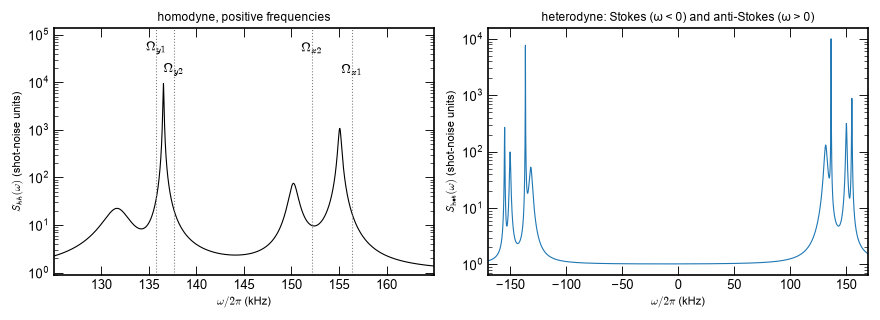

In [ ]:
S_hh = mtrap.homodyne_spectrum(LAM)
S_het = mtrap.heterodyne_spectrum(LAM)

f = mtrap.ω_range / kHz          # ordinary frequency in kHz, for plotting
band = (f > 125) & (f < 165)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.semilogy(f[band], S_hh[band], color='k')
for ii, (label, dim) in enumerate(sorted(mtrap.dimensions.items(), key=lambda item: item[1].Ω)):
    ax1.axvline(dim.Ω / kHz, ls=':', lw=1, color='grey')
    ax1.text(dim.Ω / kHz, (1.4 if ii % 2 else 4) * S_hh[band].max(), f'$\\Omega_{{{label[0]}{label[1:]}}}$',
             ha='center', va='bottom', fontsize=12)
ax1.set_ylim(top=15 * S_hh[band].max())
ax1.set_xlim(f[band][0], f[band][-1])
ax1.set_xlabel(r'$\omega / 2\pi$ (kHz)')
ax1.set_ylabel(r'$S_{hh}(\omega)$ (shot-noise units)')
ax1.set_title('homodyne, positive frequencies', fontsize=11)

ax2.semilogy(f, S_het, color='tab:blue')
ax2.set_xlim(f[0], f[-1])
ax2.set_xlabel(r'$\omega / 2\pi$ (kHz)')
ax2.set_ylabel(r'$S_\mathrm{het}(\omega)$ (shot-noise units)')
ax2.set_title('heterodyne: Stokes (ω < 0) and anti-Stokes (ω > 0)', fontsize=11)
fig.tight_layout()

far = np.argmin(np.abs(f))
print(f'at ω = 0: S_hh = {S_hh[far]:.4f}, S_het = {S_het[far]:.4f} (shot noise = 1)')
print(f'largest anti-Stokes peak {S_het[f > 0].max():.0f} at {f[f > 0][np.argmax(S_het[f > 0])]:.2f} kHz;'
      f' largest Stokes peak {S_het[f < 0].max():.0f} at {f[f < 0][np.argmax(S_het[f < 0])]:.2f} kHz')

The dotted lines are the bare trap frequencies. The two $x$ peaks sit *below* their bare
frequencies: that is the optical spring of a red-detuned cavity (section 4). The $y$ motions do not
give one peak each, but a broad peak near 131.7 kHz, below both bare frequencies, and a tall narrow
one at 136.5 kHz, between them - collective modes, as section 4 shows. In the heterodyne spectrum
each anti-Stokes sideband ($\omega > 0$, photons scattered up towards the cavity resonance, which
removes phonons) is larger than the Stokes one at $-\omega$, as expected for cooling: the largest peaks are 10045 against 7709 at $\pm 136.53$ kHz.

## 3. Position spectra

`all_position_power_spectra` returns the power spectral density of every dimensionless position
$\hat q_{j_n} = \hat b_{j_n} + \hat b_{j_n}^\dagger$ (in units of its zero-point fluctuation; pass
`zpf_scaled=False` for m²/Hz-type units), as an array and as a dict keyed by label.

x1: peak at 155.08 kHz
y1: peak at 136.53 kHz
x2: peak at 155.07 kHz
y2: peak at 136.53 kHz


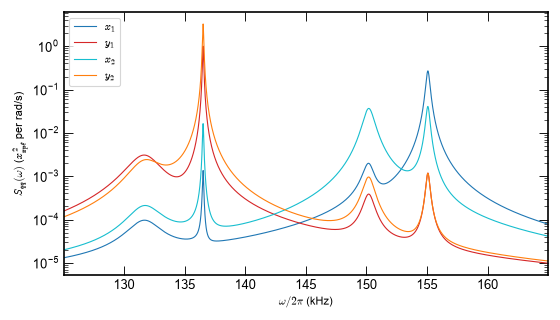

In [ ]:
psd_array, psd = mtrap.all_position_power_spectra(LAM)

fig, ax = plt.subplots(figsize=(7, 4))
colours = dict(x1='tab:blue', x2='tab:cyan', y1='tab:red', y2='tab:orange')
for label, S in psd.items():
    ax.semilogy(f[band], S[band], color=colours[label], label=f'${label[0]}_{label[1:]}$')
ax.set_xlim(f[band][0], f[band][-1])
ax.set_xlabel(r'$\omega / 2\pi$ (kHz)')
ax.set_ylabel(r'$S_{qq}(\omega)$ ($x_\mathrm{zpf}^2$ per rad/s)')
ax.legend(fontsize=10, loc='upper left')
fig.tight_layout()
for label, S in psd.items():
    print(f'{label}: peak at {f[band][np.argmax(S[band])]:.2f} kHz')

$y_1$ and $y_2$, whose bare frequencies are 1.8 kHz apart, peak at the *same* frequency, 136.5 kHz,
with a broad shoulder near 131.7 kHz: the cavity has hybridised them into collective modes. The
$x$ motions are hybridised less: $x_1$ peaks at 155.1 kHz, and $x_2$ has a broad peak of its own at
150.2 kHz and a narrow one, slightly higher, at $x_1$'s frequency. To see what the peaks are, look at
the normal modes.

## 4. Normal modes and the optical spring

The quantum Langevin equations are $\dot{\hat{\mathbf c}} = \mathbf A \hat{\mathbf c} + \hat{\mathbf c}_\text{in}$
(`mtrap.drift_matrix`). Each eigenvalue $\lambda_k = -i\Omega_k - \gamma_k/2$ of $\mathbf A$ is a
normal mode with frequency $\Omega_k$ and energy damping rate $\gamma_k$, and the size of each
eigenvector's components on $\hat b_{j_n}$, $\hat b_{j_n}^\dagger$ tells which motions take part in it.

In [ ]:
λ, vectors = np.linalg.eig(mtrap.drift_matrix)
order = np.argsort(λ.imag)                    # Im λ = -Ω: positive-frequency modes first
print(' Ω_k/2π (kHz)   γ_k/2π (kHz)   weight on  x1    y1    x2    y2')
normal_modes = []
for k in order:
    Ω_k, γ_k = -λ[k].imag, -2 * λ[k].real
    if not 0 < Ω_k < 300 * kHz:               # skip the cavity-like modes and the ω < 0 copies
        continue
    v = np.abs(vectors[:, k])**2
    weights = np.array([v[i] + v[i + 1] for i in range(2, mtrap.num_operators, 2)])
    weights /= weights.sum()
    normal_modes.append((Ω_k, γ_k))
    print(f'{Ω_k / kHz:13.3f}   {γ_k / kHz:12.4f}   ' + '  '.join(f'{w:4.2f}' for w in weights))

 Ω_k/2π (kHz)   γ_k/2π (kHz)   weight on  x1    y1    x2    y2
      155.077         0.3265   0.86  0.00  0.13  0.00
      150.195         0.9405   0.05  0.01  0.92  0.03
      136.528         0.0936   0.00  0.23  0.00  0.76
      131.686         2.8039   0.01  0.53  0.03  0.42


The $x$ normal modes are mostly single-particle motions (86% $x_1$ and 92% $x_2$), shifted down by
1.26 and 1.93 kHz from their bare frequencies. The two $y$ modes are mixtures of $y_1$ and $y_2$: a
*bright* one at 131.7 kHz, damped at 2.80 kHz - more than the 1.04 kHz that either $y$ motion
would get alone in the cavity (`cooling_rate` in section 1) - and a nearly *dark* one at 136.5 kHz,
damped at only 0.094 kHz.

For a single motion, the weak-coupling optical spring and optical damping are

$$
\delta\Omega = |G|^2\left[\frac{\Delta + \Omega}{(\Delta + \Omega)^2 + \kappa^2/4} + \frac{\Delta - \Omega}{(\Delta - \Omega)^2 + \kappa^2/4}\right],
\qquad
\Gamma_\text{opt} = |G|^2\kappa\left[\frac{1}{(\Delta + \Omega)^2 + \kappa^2/4} - \frac{1}{(\Delta - \Omega)^2 + \kappa^2/4}\right],
$$

with levisim's $\Delta = \omega_\text{tw} - \omega_\text{c} < 0$ for red detuning. Check them against the
exact normal mode of particle 1's $x$ motion alone in the cavity:

In [ ]:
single = MultiTrap(num_traps=1, Cartesian_axes_per_trap=1, gas_kwargs=DEFAULT_gas_kwargs,
                   cavity_kwargs=DEFAULT_cavity_kwargs, ω_range=np.array([0.0]))
dim = single.dimensions['x1']
Δ, κ, Ω, G2 = single.cavity.Δ, single.cavity.κ, dim.Ω, abs(dim.G)**2
δΩ_formula = G2 * ((Δ + Ω) / ((Δ + Ω)**2 + κ**2 / 4) + (Δ - Ω) / ((Δ - Ω)**2 + κ**2 / 4))
Γ_formula = G2 * κ * (1 / ((Δ + Ω)**2 + κ**2 / 4) - 1 / ((Δ - Ω)**2 + κ**2 / 4))

λ1 = np.linalg.eigvals(single.drift_matrix)
λ1 = λ1[np.argmin(np.abs(λ1.imag + Ω))]      # the mechanical eigenvalue at +Ω
print(f'optical spring  δΩ/2π: formula {δΩ_formula / kHz:+.4f} kHz, exact {(-λ1.imag - Ω) / kHz:+.4f} kHz')
print(f'optical damping Γ/2π : formula {Γ_formula / kHz:.4f} kHz (= Dimension.cooling_rate {dim.cooling_rate / kHz:.4f}),'
      f' exact {-2 * λ1.real / kHz:.4f} kHz')
Ω_pair = max(Ω_k for Ω_k, _ in normal_modes)  # the x1-like mode of the two-particle system (table above)
print(f'x1 normal mode: alone {-λ1.imag / kHz:.3f} kHz, with the second particle {Ω_pair / kHz:.3f} kHz')

optical spring  δΩ/2π: formula -1.9068 kHz, exact -1.9190 kHz
optical damping Γ/2π : formula 1.0767 kHz (= Dimension.cooling_rate 1.0767), exact 1.0726 kHz
x1 normal mode: alone 154.419 kHz, with the second particle 155.077 kHz


The weak-coupling formulas are within about 0.6% of the exact eigenvalue, which includes the
coupling to all orders. The second particle moves the $x_1$ mode by a further 0.66 kHz, because the
cavity also couples it to $x_2$, and the $y$ modes much more, because $y_1$ and $y_2$ are closer
together than their optical damping allows the cavity to resolve.

## 5. A check worth making: is there a steady state?

Every normal mode in the table of section 4 has positive damping, so this system relaxes to a
steady state. That is not guaranteed. With levisim's built-in tweezer phases, 0° and 90°, the same
particles have a normal mode with **negative** damping, which grows instead of decaying, so there
is no steady state. Its spectra would still come out finite, because a Lorentzian
$1/[(\omega - \Omega_k)^2 + \gamma_k^2/4]$ does not care about the sign of $\gamma_k$:
frequency-domain spectra cannot tell a stable system from an unstable one. levisim therefore checks
the eigenvalues of the drift matrix whenever it builds a system and logs a WARNING for an unstable
one (on stderr, which the rendered documentation leaves out), and the time-domain route to the
steady state refuses it:

In [ ]:
growth = np.max(np.linalg.eigvals(mtrap.drift_matrix).real)
print(f'φ2 = 30°: largest Re λ = {growth:.1f} /s (negative: every normal mode decays)')

# the same particles with the built-in tweezer phases, 0° and 90°
phases_0_90 = MultiTrap(num_traps=2, Cartesian_axes_per_trap=2, gas_kwargs=DEFAULT_gas_kwargs,
                        cavity_kwargs=DEFAULT_cavity_kwargs, ω_range=np.array([0.0]))
λ_90 = np.linalg.eigvals(phases_0_90.drift_matrix)
grows = λ_90[np.argmax(λ_90.real)]
print(f'φ2 = 90°: largest Re λ = {grows.real:.1f} /s (positive: the mode at {abs(grows.imag) / kHz:.2f} kHz'
      f' grows at {2 * grows.real / kHz:.3f} kHz·2π)')
try:
    steady_state_covariance(phases_0_90)
except ValueError as error:
    print('steady_state_covariance:', error)

φ2 = 30°: largest Re λ = -294.0 /s (negative: every normal mode decays)
φ2 = 90°: largest Re λ = 2677.5 /s (positive: the mode at 134.92 kHz grows at 0.852 kHz·2π)
steady_state_covariance: MultiTrap(2×2) is unstable (largest Re eigenvalue 2.678e+03), so it has no steady state


2026-11-19 19:51:17.864 | WARNING  | levisim.multiphysics.multitrap.base:_check_linear_stability:357 - MultiTrap(2×2): 2 of the 10 drift-matrix eigenvalues have a positive real part (largest Re λ = +2678 /s, an e-folding time of 0.373 ms, on the mode at |Im λ| = 134.92 kHz), so the linearised dynamics are unstable and have no steady state: the stationary spectra are formally finite but do not describe a physical steady state. Check the detuning Δ, the couplings and the tweezer phases φn.


The instability comes from the $90^\circ$ phase between the two tweezers: it makes the
cavity-mediated coupling between the near-degenerate $y_1$ and $y_2$ non-reciprocal, and one
collective mode gains energy. [`06_parameter_sweeps`](06_parameter_sweeps.ipynb) maps it against the
tweezer phase. At $\phi_2 = 30^\circ$ the steady state exists and can be found both ways - from the
Lyapunov equation (time domain) and by integrating the position spectra, since
$\int S_{qq}\,d\omega/2\pi = \langle \hat q^2\rangle = 2n + 1$:

In [ ]:
steady = MultiTrap(
    num_traps=2, Cartesian_axes_per_trap=2, φn_dict={2: 30 * degrees},
    gas_kwargs=DEFAULT_gas_kwargs, cavity_kwargs=DEFAULT_cavity_kwargs,
    ω_range=[np.arange(-3000, 3000, 1.0) * kHz,       # wide enough for the tails
             np.arange(125, 165, 0.002) * kHz,         # resolve every peak, both signs of ω
             np.arange(-165, -125, 0.002) * kHz],
)
V = steady_state_covariance(steady)
_, psd_steady = steady.all_position_power_spectra(LAM)
print(f'{len(steady.ω_range)} frequency points')
for label in steady.labels:
    V_label = dimension_covariance(steady, V, [label])
    q2_lyapunov = V_label[0, 0]
    q2_spectrum = np.trapezoid(psd_steady[label], steady.ω_range) / (2 * np.pi)
    print(f'{label}: n = {mean_phonon_numbers(V_label)[0]:6.1f} phonons; <q²> Lyapunov {q2_lyapunov:8.3f},'
          f' ∫S dω/2π {q2_spectrum:8.3f} (relative difference {q2_spectrum / q2_lyapunov - 1:+.1e})')

45998 frequency points
x1: n =  139.0 phonons; <q²> Lyapunov  281.486, ∫S dω/2π  281.478 (relative difference -2.7e-05)
y1: n =  161.1 phonons; <q²> Lyapunov  322.108, ∫S dω/2π  322.103 (relative difference -1.5e-05)
x2: n =   76.4 phonons; <q²> Lyapunov  154.964, ∫S dω/2π  154.955 (relative difference -6.0e-05)
y2: n =  486.2 phonons; <q²> Lyapunov  981.463, ∫S dω/2π  981.456 (relative difference -6.9e-06)


The two routes agree to better than $10^{-4}$, the residue coming from the truncated tails of the
integral. $y_2$ is by far the hottest motion. Each normal mode settles roughly where its optical
damping balances the heating by the gas and by photon recoil,
$n \approx (\Gamma n_\text{th} + \Gamma_\text{rec})/\gamma_k$, and the cavity shares its
damping very unequally between the hybridised modes:

In [ ]:
heating = np.mean([dim.Γ * dim.noise_phonons_exact + mtrap.recoil_heating_rate_dict[label] for label, dim in mtrap.dimensions.items()])
print(f'gas and recoil heating Γ·n_th + Γ_rec ≈ {heating:.3e} phonons/s per motion')
for Ω_k, γ_k in normal_modes:
    print(f'normal mode at {Ω_k / kHz:.3f} kHz: γ_k/2π = {γ_k / kHz:.4f} kHz, (Γ·n_th + Γ_rec)/γ_k = {heating / γ_k:5.0f} phonons')

# the same estimate for particle 1's x motion alone in the cavity (`single`, section 4)
V_single = steady_state_covariance(single)
dim = single.dimensions['x1']
n_single = mean_phonon_numbers(dimension_covariance(single, V_single, ['x1']))[0]
heating_single = dim.Γ * dim.noise_phonons_exact + single.recoil_heating_rate_dict['x1']
print(f'\nx1 alone: (Γ·n_th + Γ_rec)/γ = {heating_single / (-2 * λ1.real):.1f} phonons,'
      f' Lyapunov n = {n_single:.1f} phonons')

gas and recoil heating Γ·n_th + Γ_rec ≈ 3.299e+05 phonons/s per motion
normal mode at 155.077 kHz: γ_k/2π = 0.3265 kHz, (Γ·n_th + Γ_rec)/γ_k =   161 phonons
normal mode at 150.195 kHz: γ_k/2π = 0.9405 kHz, (Γ·n_th + Γ_rec)/γ_k =    56 phonons
normal mode at 136.528 kHz: γ_k/2π = 0.0936 kHz, (Γ·n_th + Γ_rec)/γ_k =   561 phonons
normal mode at 131.686 kHz: γ_k/2π = 2.8039 kHz, (Γ·n_th + Γ_rec)/γ_k =    19 phonons

x1 alone: (Γ·n_th + Γ_rec)/γ = 46.3 phonons, Lyapunov n = 46.7 phonons


The nearly dark $y$ mode, damped at 0.094 kHz, would settle near 561 phonons, and $y_2$, three quarters of that mode, ends up at 486; the bright $y$ mode, damped at 2.8 kHz, near 19. For a
particle alone in the cavity the estimate is within 1% of the exact occupation (the rest is quantum
backaction from Stokes scattering). With two particles it is only a guide, because each motion is a
mixture of normal modes whose noise the cavity correlates.

**Next:** [`02_seven_methods_agree`](02_seven_methods_agree.ipynb) computes these spectra by all seven
routes; [`03_stochastic_free_space`](03_stochastic_free_space.ipynb) turns to the classical simulator of
a single bead in free space.